## New Usage in this Project 

| Name | Object Type | Input | Package | Description |
| --- | --- | --- | --- | --- |
| argsort() | function | list/numpy array | numpy | returns the indices that would sort an array |

In [484]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import Delaunay
import matplotlib.animation as animation

In [485]:
# To install the required packages: sudo apt install python3-xyz

## Extract the size of the Domain

In [486]:
file = open("output/domain.gnu")
fileString = file.read().split("\n")
file.close()
x_min, y_min = [int(x) for x in fileString[0].split()]
x_max, y_max = [int(x) for x in fileString[2].split()]
domain_X = (x_min, x_max)
domain_Y = (y_min, y_max)
domain_X, domain_Y

((0, 10), (0, 10))

## Plot some V-cells

In [487]:
def get_Voronoi_Cells_from_File(filename):
    file = open(filename)
    fileString = file.read().split("\n")
    file.close()
    Cells = {}
    for i in range(len(fileString) - 1):

        # Retrieve seed ID, seed location, and vertices from output file
        cell_string = fileString[i].split()
        seed_ID = int(cell_string[0])   # seed ID
        seed_loc = np.array([float(cell_string[1]), float(cell_string[2])])     # seed location
        vertices = []
        for j in range(3, len(cell_string)):
            vertex = [float(x) for x in cell_string[j][1:-1].split(",")]
            vertices.append(vertex)
        vertices = np.array(vertices)   # vertices that bound the region

        #  Sort vertices in traversal order
        angles = np.arctan2(vertices[:, 1] - seed_loc[1], vertices[:, 0] - seed_loc[0])
        vertices = vertices[np.argsort(angles)]
        vertices = np.vstack([vertices, vertices[0]])

        # Add to dictionary
        Cells[seed_ID] = {"seed": seed_loc, "vertices": np.column_stack(vertices)}
    return Cells

In [488]:
def get_IDs(Cells):
    return [cell_ID for cell_ID in Cells.keys()]

def get_Seeds(Cells):
    return np.array([cell['seed'] for cell in Cells.values()])

def get_Vertices(Cells):
    return [cell['vertices'] for cell in Cells.values()]

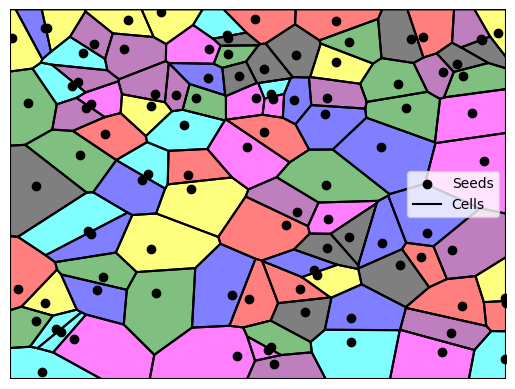

In [489]:
Cells = get_Voronoi_Cells_from_File("output/cellID_loc_vert.txt")
fig, ax = plt.subplots()
colors = ["blue", "green", "red", "purple", "cyan", "magenta", "yellow", "black"]
for seed_ID, data in Cells.items():
    seed_loc, vertices = data['seed'], data['vertices']
    ax.scatter(seed_loc[0], seed_loc[1], color="black", zorder=2)
    ax.plot(vertices[0], vertices[1], color="black")
    ax.fill(vertices[0], vertices[1], color=colors[seed_ID % len(colors)], alpha=0.5)
ax.set_xlim(domain_X)
ax.set_ylim(domain_Y)
ax.set_axis_off()
ax.legend(["Seeds", "Cells"])


## Print the Centroids

In [490]:
def get_Centroids_from_File(filename):
    file = open(filename)
    fileString = file.read().split()
    file.close()
    centroids = []

    points = [float(x) for x in fileString]
    for i in range(int(len(points)/3)):
        centroids.append(points[3*i+1:3*(i+1)])

    return np.column_stack(centroids)

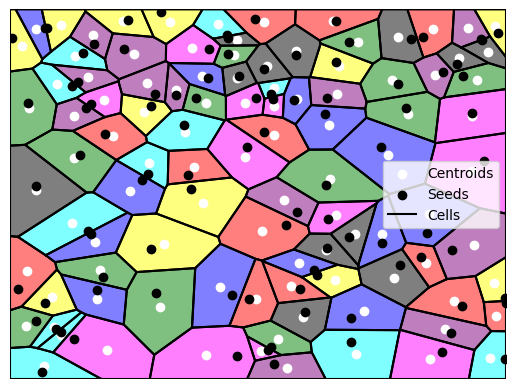

In [501]:
Cells = get_Voronoi_Cells_from_File("output/cellID_loc_vert.txt")
Centroids = get_Centroids_from_File("output/centroids.txt")
fig, ax = plt.subplots()
ax.scatter(Centroids[0], Centroids[1], color="white", zorder=2)
for seed_ID, data in Cells.items():
    seed_loc, vertices = data['seed'], data['vertices']
    ax.scatter(seed_loc[0], seed_loc[1], color="black", zorder=2)
    ax.plot(vertices[0], vertices[1], color="black", zorder=2)
    ax.fill(vertices[0], vertices[1], color=colors[seed_ID % len(colors)], alpha=0.5)
ax.set_xlim(domain_X)
ax.set_ylim(domain_Y)
ax.set_axis_off()
ax.legend(["Centroids", "Seeds", "Cells"])

## Python's Delaunay Triangularization

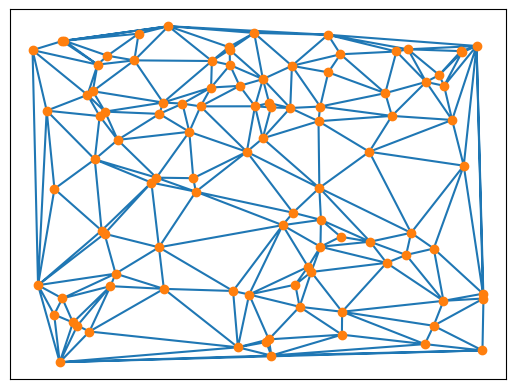

In [500]:
Cells = get_Voronoi_Cells_from_File("output/cellID_loc_vert.txt")
seeds = get_Seeds(Cells)
tri = Delaunay(seeds)
fig, ax = plt.subplots()
ax.set_xticks([])
ax.set_yticks([])
ax.triplot(seeds[:,0], seeds[:,1], tri.simplices, "-o")

## Animate LLoyd's Algo

In [493]:
from matplotlib import rc
rc('animation', html='jshtml')

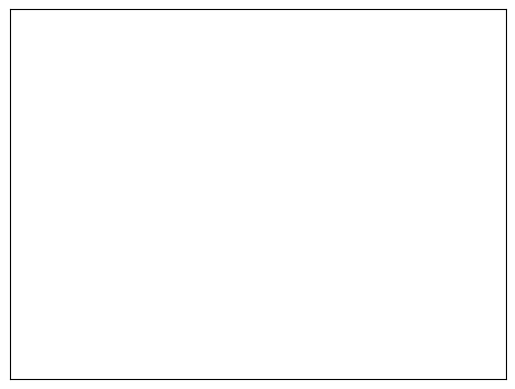

In [494]:
iterations = 30
colors = ["blue", "green", "red", "purple", "cyan", "magenta", "yellow", "black"]
fig, ax = plt.subplots()
ax.set_xticks([])
ax.set_yticks([])

ims = []
for i in range(iterations+1):
    Cells = get_Voronoi_Cells_from_File(f"output/lloyd/cellset{i}.gnu")
    CIDs = get_IDs(Cells)
    seeds = get_Seeds(Cells)
    vertices = get_Vertices(Cells)
    
    frame_artists = []
    for j in range(len(CIDs)):
        seed_ID, seed_loc, verts = CIDs[j], seeds[j], vertices[j]

        # artist0, = ax.plot(seed_loc[0], seed_loc[1], "o", color="black", zorder=2)
        # frame_artists.append(artist0)
        artist1, = ax.plot(verts[0], verts[1], color="black")
        frame_artists.append(artist1)
        artist2, = ax.fill(verts[0], verts[1], color=colors[seed_ID % len(colors)], alpha=0.5)
        frame_artists.append(artist2)

    ims.append(frame_artists)
    
ani = animation.ArtistAnimation(fig, ims, blit=True)

In [495]:
ani.save("unnamed_2d_animation.gif", writer=animation.PillowWriter(fps=10))

## The Final iteration of Lloyd's Algo

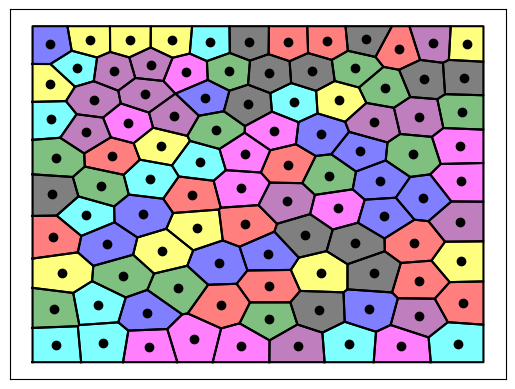

In [497]:
fig, ax = plt.subplots()
ax.set_xticks([])
ax.set_yticks([])
for seed_ID, data in Cells.items():
    seed_loc, vertices = data['seed'], data['vertices']
    
    ax.scatter(seed_loc[0], seed_loc[1], color="black", zorder=2)
    ax.plot(vertices[0], vertices[1], color="black", zorder=2)
    ax.fill(vertices[0], vertices[1], color=colors[seed_ID % len(colors)], alpha=0.5)